TimeSHAP: mean (SD) over the repetitions


source,pattern,key number,ground truth,true logit,GRU,TabPFN
0,T1,event: visit 20,1.5 (0.0),1.5 (0.0),1.44 (0.26),1.53 (0.28)
1,T1,feature: code 1,1.5 (0.0),1.5 (0.0),1.46 (0.23),1.52 (0.26)
2,T1,"cell: visit 20, code 1",1.5 (0.0),1.5 (0.0),1.47 (0.24),1.54 (0.27)
3,T1,players (event level),2.0 (0.0),2.0 (0.0),2.7 (0.81),4.8 (0.57)
4,T1,cell level ran (%),100.0 (0.0),100.0 (0.0),100.0 (0.0),100.0 (0.0)
5,T1,MAE event level,-,0.0 (0.0),0.01 (0.0),0.01 (0.0)
6,T1,MAE feature level,-,0.0 (0.0),0.04 (0.01),0.05 (0.01)
7,T1,MAE cell level,-,0.0 (0.0),0.0 (0.0),0.0 (0.0)
8,T1,seconds per person,-,0.06 (0.0),0.03 (0.01),34.31 (6.51)
9,T2,event: visit 18,1.5 (0.0),1.5 (0.0),1.71 (0.57),1.76 (0.49)


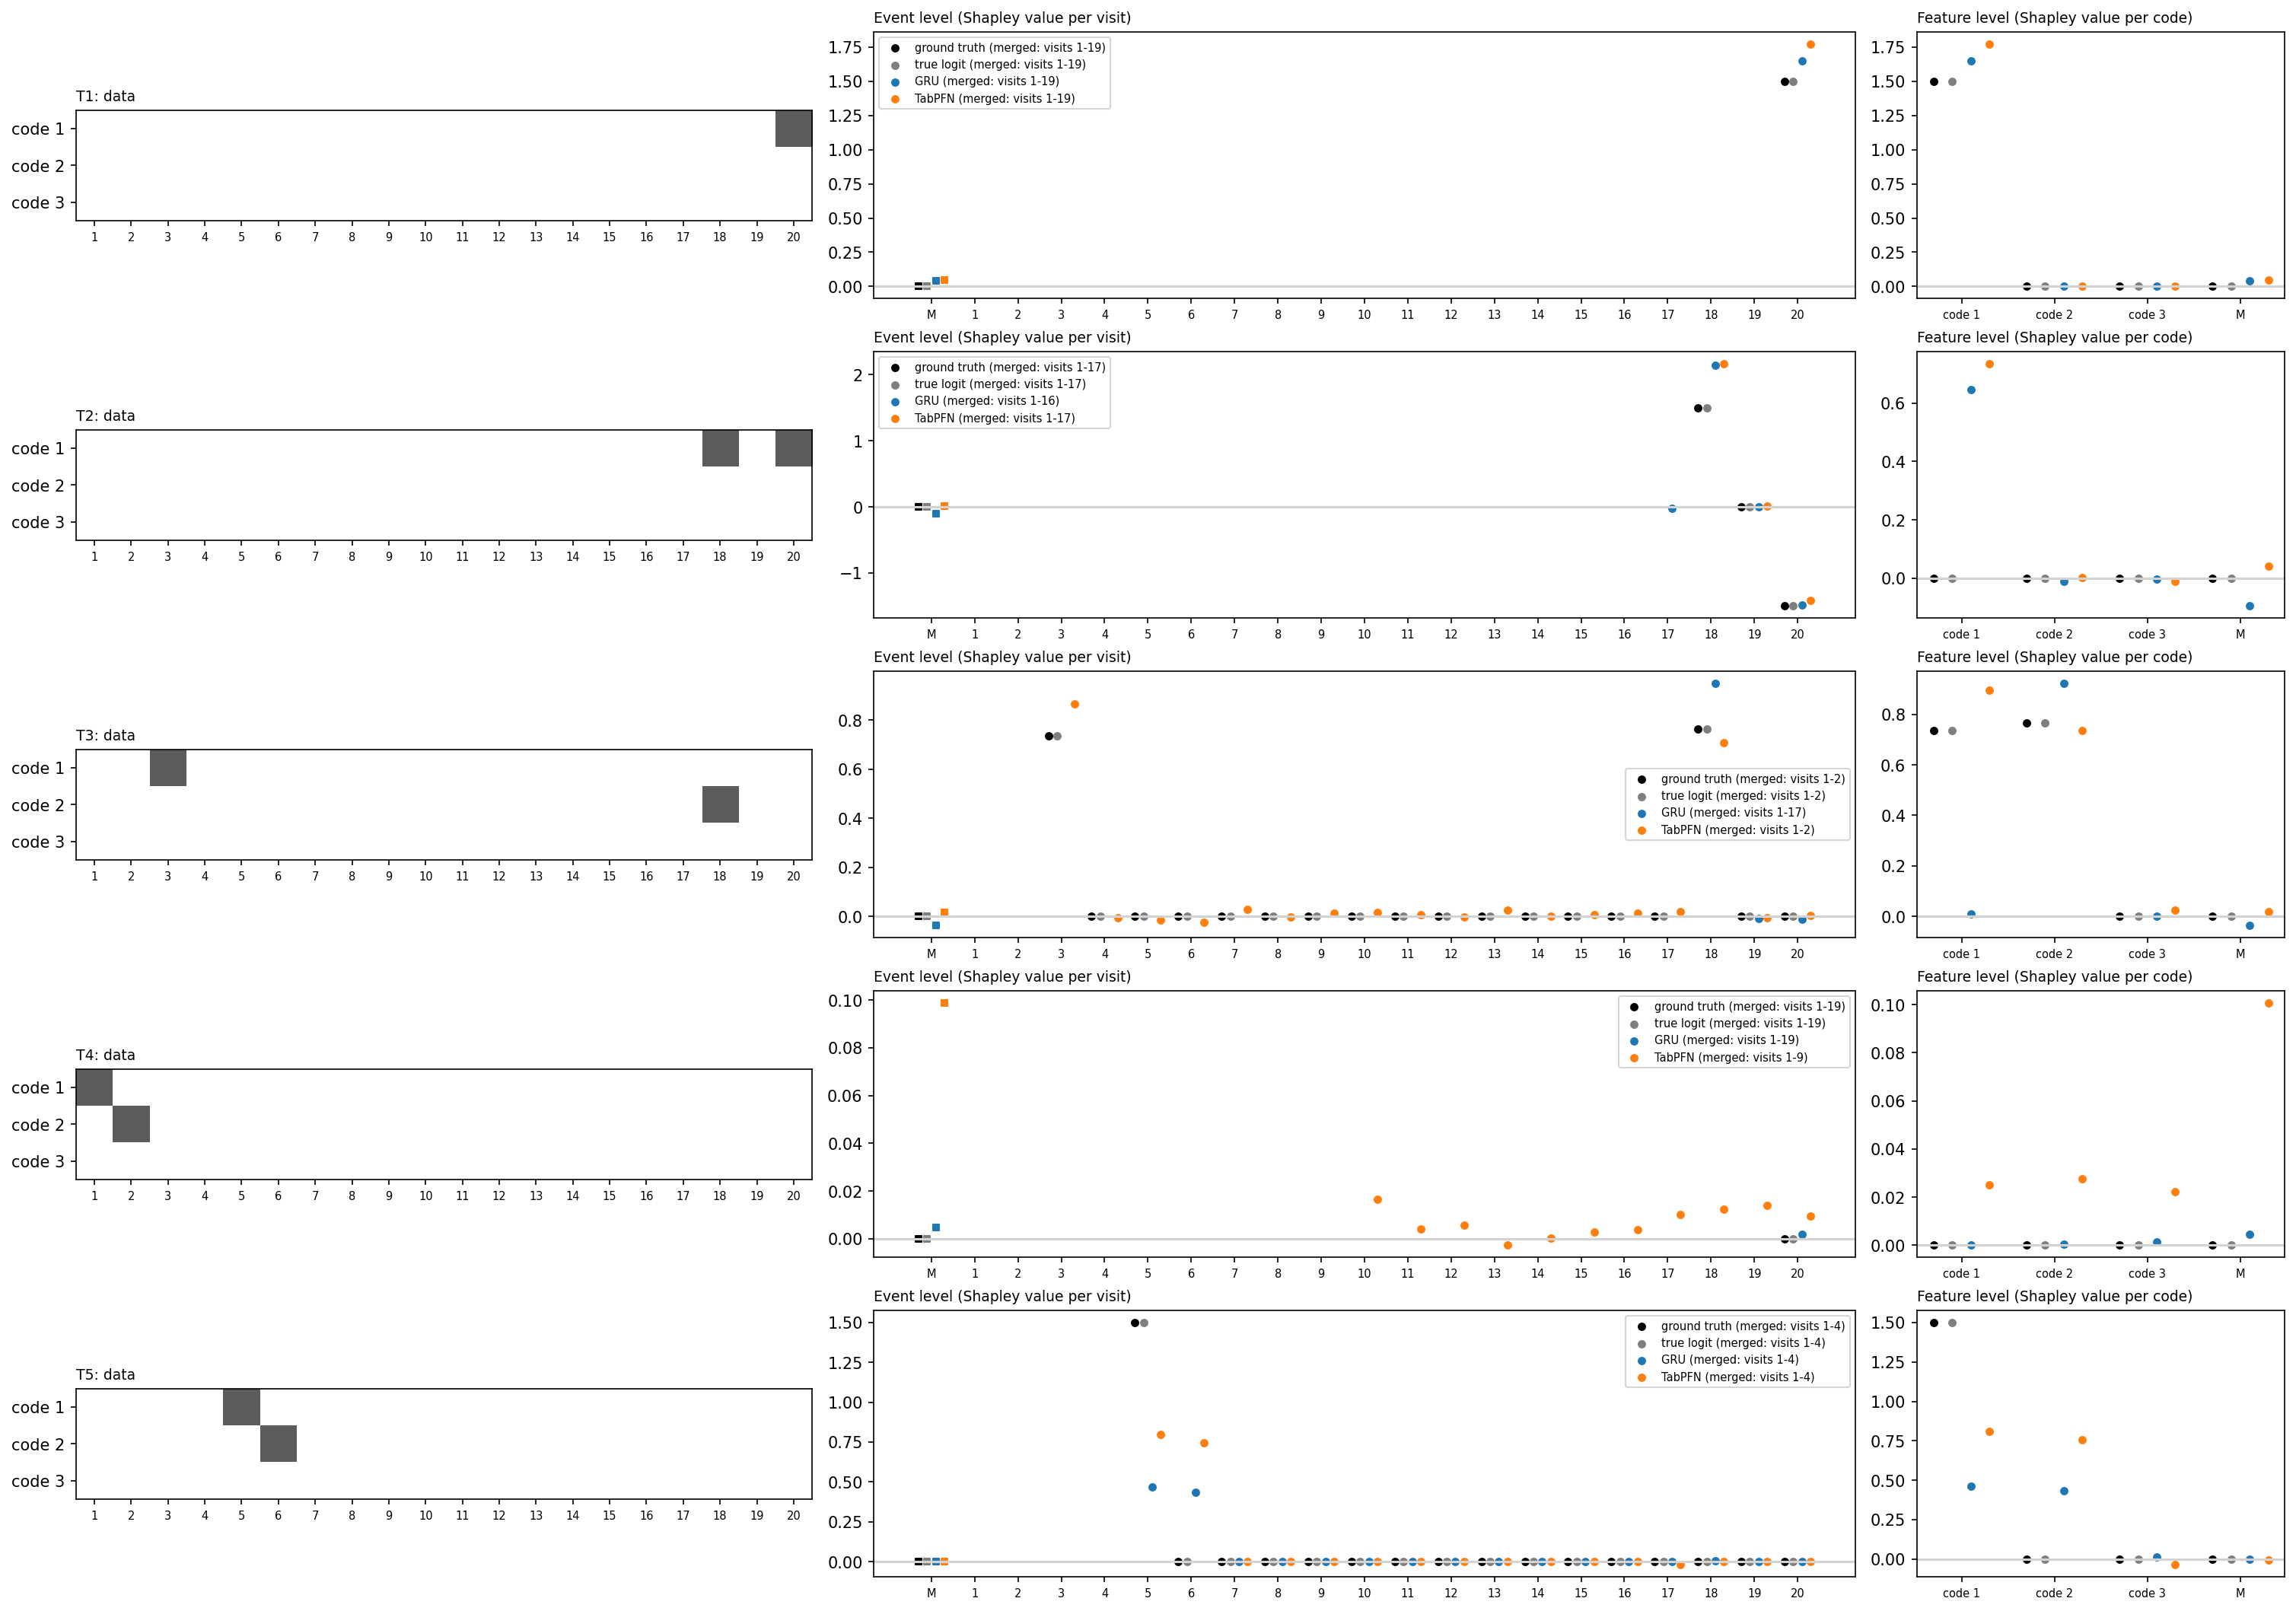

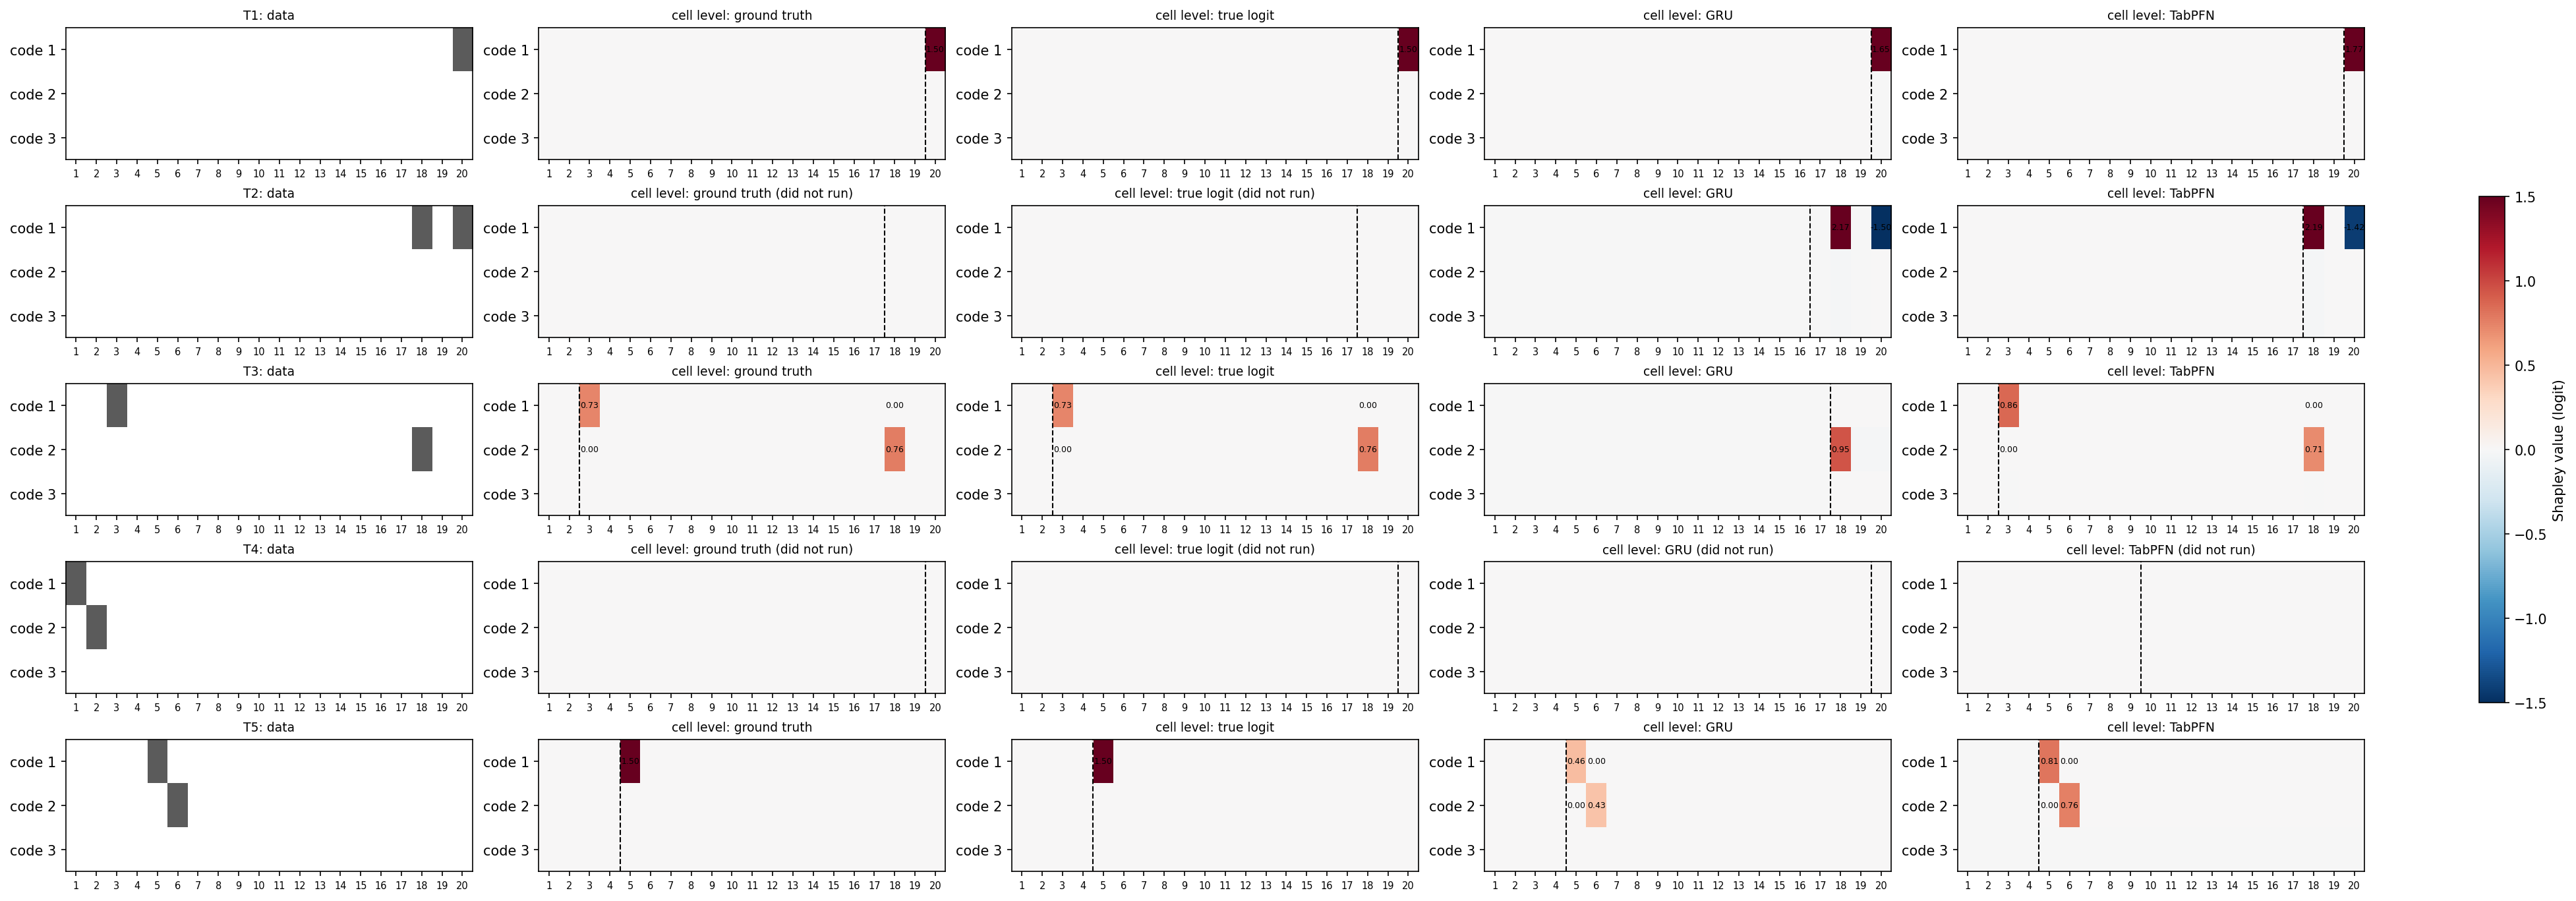

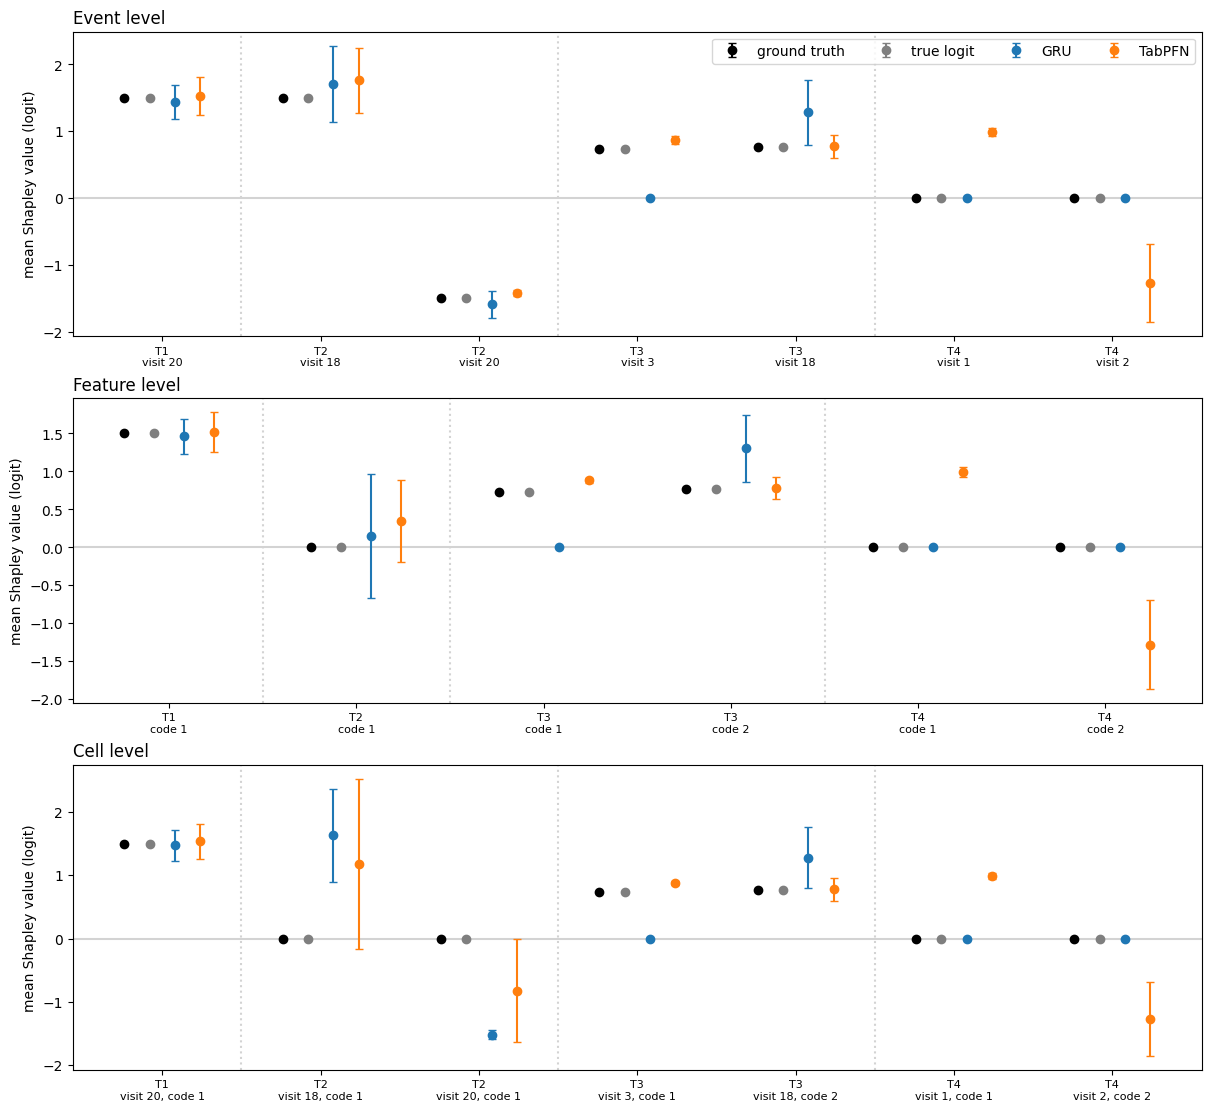

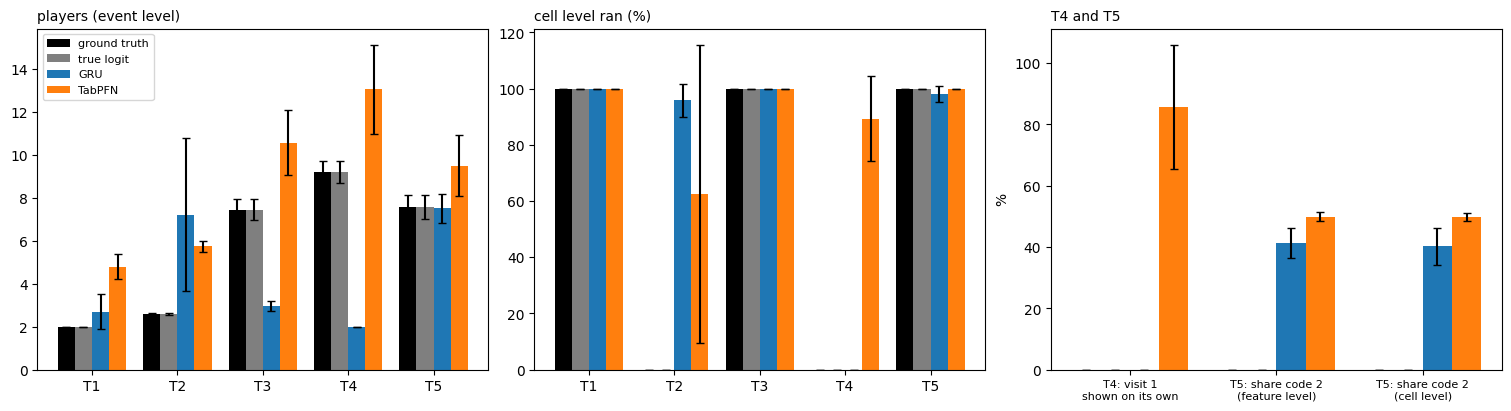

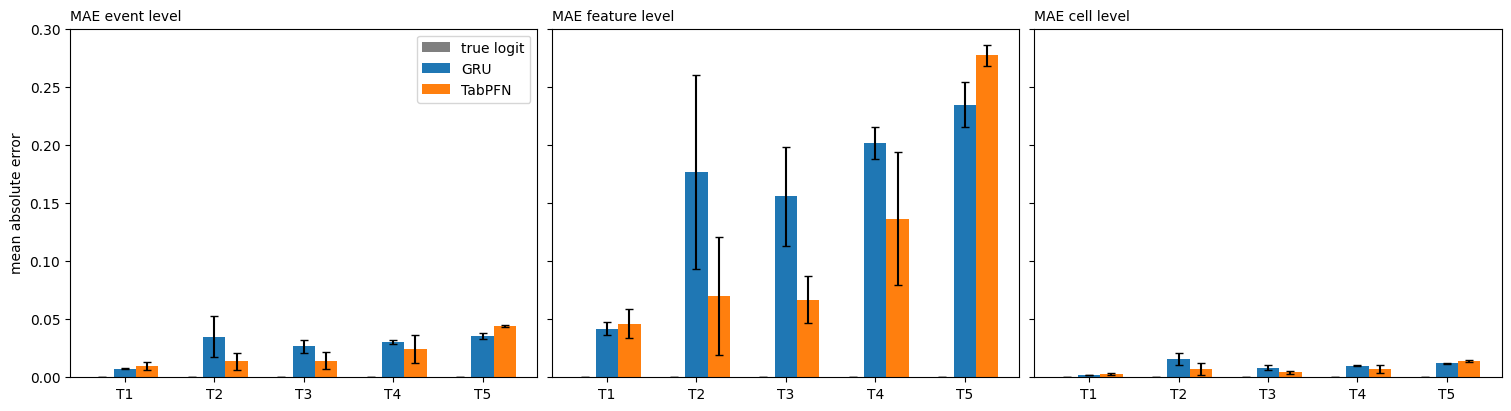

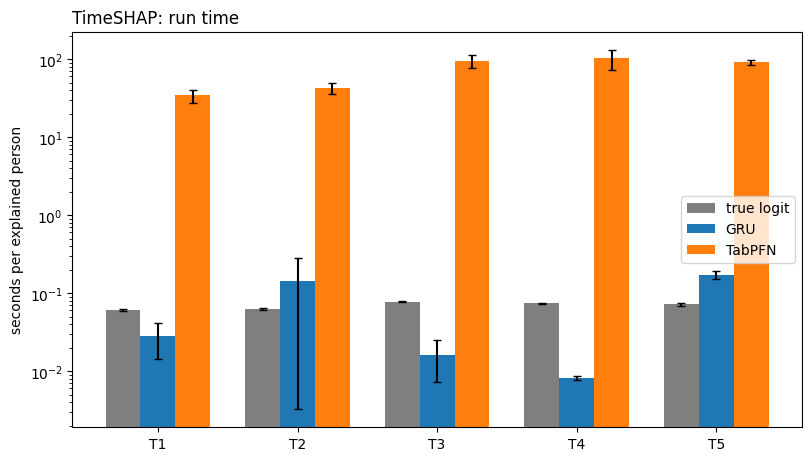

source,ground truth,true logit,GRU,TabPFN
rep,,,,
0,0.0,0.0,0.0,100.0
1,0.0,0.0,0.0,71.4


In [1]:
#.......................................................................................
# Plot the results of the TimeSHAP simulation (analogous to the WindowSHAP plots)
# Reads results_timeshap.csv, figure_timeshap.png and figure_timeshap_cells.png
# (written by simulation_TimeSHAP.py). Run it in Positron/Jupyter in the same folder.
#.......................................................................................

#.......................................................................................
# Load the results
#.......................................................................................

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

results = pd.read_csv("results_timeshap.csv")

sources = ["ground truth", "true logit", "GRU", "TabPFN"]
models = ["true logit", "GRU", "TabPFN"]
patterns = ["T1", "T2", "T3", "T4", "T5"]
colors = {"ground truth": "black", "true logit": "tab:grey", "GRU": "tab:blue", "TabPFN": "tab:orange"}

means = results.groupby(["pattern", "key number", "source"])["value"].mean()
sds = results.groupby(["pattern", "key number", "source"])["value"].std().fillna(0)

#.......................................................................................
# 1. Table: mean (SD) over the repetitions
#.......................................................................................

m = results.groupby(["pattern", "key number", "source"], sort=False)["value"].mean().unstack()
s = results.groupby(["pattern", "key number", "source"], sort=False)["value"].std().unstack()

table = m.round(2).astype(str) + " (" + s.fillna(0).round(2).astype(str) + ")"
table = table.where(m.notna(), "-")[sources]

# rows in the order in which they were computed
order = list(results[["pattern", "key number"]].drop_duplicates().itertuples(index=False, name=None))
print("TimeSHAP: mean (SD) over the repetitions")
display(table.loc[order].reset_index())

#.......................................................................................
# 2. Figures of the example persons (last repetition)
#.......................................................................................

display(Image("figure_timeshap.png"))          # data, event level, feature level
display(Image("figure_timeshap_cells.png"))    # cell level

#.......................................................................................
# 3. Plot: key numbers per pattern, one panel per level (event, feature, cell)
# One point per source (mean over the repetitions), bars = SD.
# The ground truth (black) is the reference.
#.......................................................................................

key_numbers = {
    "Event level": [("T1", "event: visit 20"),
                    ("T2", "event: visit 18"), ("T2", "event: visit 20"),
                    ("T3", "event: visit 3"), ("T3", "event: visit 18"),
                    ("T4", "event: visit 1"), ("T4", "event: visit 2")],
    "Feature level": [("T1", "feature: code 1"),
                      ("T2", "feature: code 1"),
                      ("T3", "feature: code 1"), ("T3", "feature: code 2"),
                      ("T4", "feature: code 1"), ("T4", "feature: code 2")],
    "Cell level": [("T1", "cell: visit 20, code 1"),
                   ("T2", "cell: visit 18, code 1"), ("T2", "cell: visit 20, code 1"),
                   ("T3", "cell: visit 3, code 1"), ("T3", "cell: visit 18, code 2"),
                   ("T4", "cell: visit 1, code 1"), ("T4", "cell: visit 2, code 2")]}

fig, axes = plt.subplots(3, 1, figsize=(12, 11), layout="constrained")

for ax, (level, keys) in zip(axes, key_numbers.items()):
    x = np.arange(len(keys))
    ax.axhline(0, color="lightgrey")
    for i, source in enumerate(sources):
        mean = [means.get((p, k, source), np.nan) for p, k in keys]
        sd = [sds.get((p, k, source), np.nan) for p, k in keys]
        ax.errorbar(x - 0.24 + 0.16 * i, mean, yerr=sd, fmt="o", capsize=3,
                    color=colors[source], label=source)

    # light grey lines between the patterns
    for b in range(1, len(keys)):
        if keys[b][0] != keys[b - 1][0]:
            ax.axvline(b - 0.5, color="lightgrey", linestyle=":")
    ax.set_xticks(x, [f"{p}\n{k.split(': ')[1]}" for p, k in keys], fontsize=8)
    ax.set_ylabel("mean Shapley value (logit)")
    ax.set_title(level, loc="left")

axes[0].legend(ncol=4)
plt.savefig("key_numbers_timeshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 4. Plot: what TimeSHAP selects (pruning and cell level)
# Left: number of players at event level (fewer = more visits merged by pruning)
# Middle: share of persons for whom the cell level ran (%)
# Right: T4 "visit 1 shown on its own" (%) and T5 share of code 2 (feature and cell level)
#.......................................................................................

fig, axes = plt.subplots(1, 3, figsize=(15, 4), layout="constrained")
x = np.arange(len(patterns))

for ax, key in zip(axes[:2], ["players (event level)", "cell level ran (%)"]):
    for i, source in enumerate(sources):
        mean = [means.get((p, key, source), np.nan) for p in patterns]
        sd = [sds.get((p, key, source), np.nan) for p in patterns]
        ax.bar(x - 0.3 + 0.2 * i, mean, width=0.2, yerr=sd, capsize=3,
               color=colors[source], label=source)
    ax.set_xticks(x, patterns)
    ax.set_title(key, loc="left", fontsize=10)

keys = [("T4", "visit 1 shown on its own (%)"),
        ("T5", "feature: share code 2"), ("T5", "cell: share code 2")]
x = np.arange(len(keys))
ax = axes[2]
for i, source in enumerate(sources):
    mean = [means.get((p, k, source), np.nan) for p, k in keys]
    # shares as %, so that all three are on the same scale
    mean = [v * 100 if "share" in k else v for v, (p, k) in zip(mean, keys)]
    sd = [sds.get((p, k, source), np.nan) for p, k in keys]
    sd = [v * 100 if "share" in k else v for v, (p, k) in zip(sd, keys)]
    ax.bar(x - 0.3 + 0.2 * i, mean, width=0.2, yerr=sd, capsize=3, color=colors[source])
ax.set_xticks(x, ["T4: visit 1\nshown on its own", "T5: share code 2\n(feature level)",
                  "T5: share code 2\n(cell level)"], fontsize=8)
ax.set_ylabel("%")
ax.set_title("T4 and T5", loc="left", fontsize=10)

axes[0].legend(fontsize=8)
plt.savefig("selection_timeshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 5. Plot: errors against the ground truth, one panel per level
# MAE over all visits (event level), codes (feature level) or cells (cell level)
#.......................................................................................

fig, axes = plt.subplots(1, 3, figsize=(15, 4), sharey=True, layout="constrained")
x = np.arange(len(patterns))

for ax, key in zip(axes, ["MAE event level", "MAE feature level", "MAE cell level"]):
    for i, model in enumerate(models):
        mean = [means.get((p, key, model), np.nan) for p in patterns]
        sd = [sds.get((p, key, model), np.nan) for p in patterns]
        ax.bar(x - 0.25 + 0.25 * i, mean, width=0.25, yerr=sd, capsize=3,
               color=colors[model], label=model)
    ax.set_xticks(x, patterns)
    ax.set_title(key, loc="left", fontsize=10)
axes[0].set_ylabel("mean absolute error")
axes[0].legend()
plt.savefig("errors_timeshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 6. Plot: run time per explained person (pruning + event + feature + cell level)
# Note: true logit and GRU run on n_jobs CPU cores, TabPFN on one GPU.
#.......................................................................................

fig, ax = plt.subplots(figsize=(8, 4.5), layout="constrained")
x = np.arange(len(patterns))
for i, model in enumerate(models):
    mean = [means.get((p, "seconds per person", model), np.nan) for p in patterns]
    sd = [sds.get((p, "seconds per person", model), np.nan) for p in patterns]
    ax.bar(x - 0.25 + 0.25 * i, mean, width=0.25, yerr=sd, capsize=3, color=colors[model], label=model)
ax.set_xticks(x, patterns)
ax.set_yscale("log")
ax.set_ylabel("seconds per explained person")
ax.set_title("TimeSHAP: run time", loc="left")
ax.legend()
plt.savefig("runtime_timeshap.png", dpi=150, bbox_inches="tight")
plt.show()

#.......................................................................................
# 7. Optional: every repetition separately, e.g. T4 (is visit 1 shown on its own?)
#.......................................................................................

t4 = results[(results["pattern"] == "T4") & (results["key number"] == "visit 1 shown on its own (%)")]
display(t4.pivot(index="rep", columns="source", values="value")[sources].round(1))